# NLP - PROJECT: SpamLens (Traditional Models)

English SMS spam detection with **TF-IDF + Multinomial Naive Bayes** and **TF-IDF + Logistic Regression**.

**How to run**
1. Open this notebook in Google Colab (CPU is enough) and run all cells from the top (`Runtime > Run all`).
2. Allow access to Google Drive when asked: the data, models and results are saved in `MyDrive/SpamLens`.
3. Run this notebook **before** `transformer_models.ipynb`, because it creates the dataset for both notebooks.

## 1. Preparation

In [ ]:
!pip install -q ftfy scikit-learn==1.9.1

In [ ]:
# Import Libraries
import json
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
# Save everything on Google Drive so it is kept after the Colab session ends
from google.colab import drive
import os

drive.mount("/content/drive")

project_folder = "/content/drive/MyDrive/SpamLens"
data_folder = os.path.join(project_folder, "data")
model_folder = os.path.join(project_folder, "models")
table_folder = os.path.join(project_folder, "results", "tables")
figure_folder = os.path.join(project_folder, "results", "figures")

for folder in [data_folder, model_folder, table_folder, figure_folder]:
    os.makedirs(folder, exist_ok=True)

print("Folder ready:", project_folder)

Mounted at /content/drive
Folder ready: /content/drive/MyDrive/SpamLens


In [ ]:
# Load the two public datasets one from uci and one from super sms
uci_url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/5339710562cc46c4a32a369d63f1e8751a18a54e/data/sms.tsv"
super_url = "https://raw.githubusercontent.com/smspamresearch/spstudy/a0889f36fb59e23a7f853a6932485d93d18b8afc/Data/super_sms_dataset.csv"

# UCI SMS Spam Collection: tab separated "label <tab> text" (quoting=3 means quotes are normal characters)
uci_data = pd.read_csv(uci_url, sep="\t", header=None, names=["label", "text"], quoting=3)

# super SMS Dataset
super_data = pd.read_csv(super_url, encoding="cp1252", encoding_errors="replace")

In [ ]:
# give both datasets the same columns: text, label (0 = ham, 1 = spam), source
uci_data = pd.DataFrame({
    "text": uci_data["text"],
    "label": (uci_data["label"] == "spam").astype(int),
    "source": "uci_sms_spam_collection"
})

super_data = super_data.dropna(subset=["SMSes", "Labels"])
super_data = pd.DataFrame({
    "text": super_data["SMSes"].astype(str),
    "label": super_data["Labels"].astype(int),
    "source": "super_sms_dataset"
})

print("UCI  :", uci_data.shape)
print("Super:", super_data.shape)
print(super_data.head())

UCI  : (5574, 3)
Super: (67008, 3)
                                                text  label             source
0  There be an update for your delivery CC 017281...      1  super_sms_dataset
1  watch your favorite english movies of all genr...      1  super_sms_dataset
2                     aur what is the status for fms      0  super_sms_dataset
3  hi shalini sundi thank you for dialling  speci...      1  super_sms_dataset
4                       m tryin to understand too...      0  super_sms_dataset


## 2. EDA

        uci  super_sms
label                 
ham    4827      40830
spam    747      26178


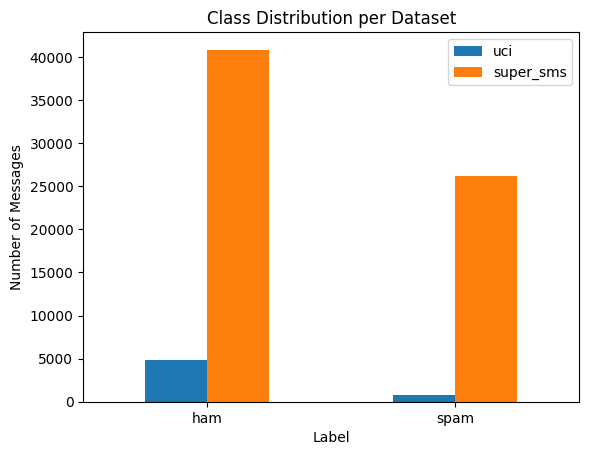

In [ ]:
# Number of ham and spam messages in each dataset
label_counts = pd.DataFrame({
    "uci": uci_data["label"].value_counts(),
    "super_sms": super_data["label"].value_counts()
}).rename(index={0: "ham", 1: "spam"})

print(label_counts)

label_counts.plot(kind="bar")
plt.title("Class Distribution per Dataset")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

Both datasets are imbalanced, and the Super SMS Dataset is much larger. The final dataset is balanced later.

         count       mean        std  min   25%   50%   75%    max
label                                                             
0      45657.0  13.142519  11.008530  1.0   6.0  10.0  17.0  286.0
1      26925.0  23.853556  10.137855  1.0  19.0  22.0  26.0  526.0


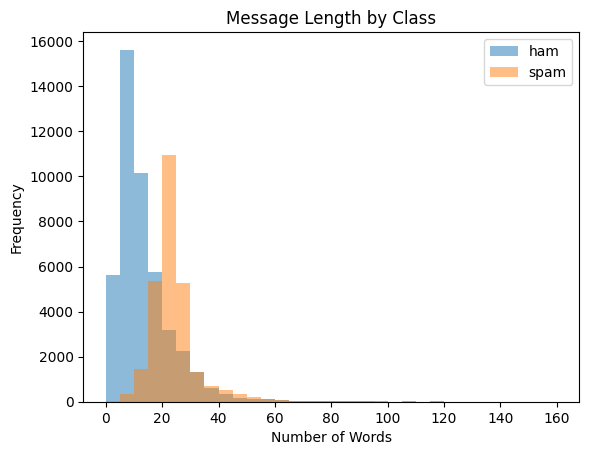

In [ ]:
# Message length in words (so basically, we would like to calculate and see the data distributions from this two dataset)
all_data = pd.concat([uci_data, super_data], ignore_index=True)
all_data["word_count"] = all_data["text"].str.split().str.len()

print(all_data.groupby("label")["word_count"].describe())

all_data[all_data["label"] == 0]["word_count"].plot(kind="hist", bins=range(0, 165, 5), alpha=0.5, label="ham")
all_data[all_data["label"] == 1]["word_count"].plot(kind="hist", bins=range(0, 165, 5), alpha=0.5, label="spam")
plt.title("Message Length by Class")
plt.xlabel("Number of Words")
plt.legend()
plt.show()

In [ ]:
# Look at sample messages
for label, label_name in [(0, "ham"), (1, "spam")]:
    print(f"\n========== {label_name} ==========")
    for text in super_data[super_data["label"] == label]["text"].sample(5, random_state=42):
        print("-", text)


========== ham ==========
- I need to go simlim get some stuff. See got what then decide but likely to be after lunch
- Oh okie lor... Cos if got nothin much den i wont go lor...
- I want to speak with you urgently.Please call me.
- Hey lao po, thks for helping me todae! lemme noe if u want to hav dinner 2gether..think i wanna go shopping at plaza sing ltr.Saw some nice clothes juz now.Haha
- Hahaha dont worry it's alright :-D

========== spam ==========
- extra day  extra savings  get extra  off   cashback above all existing discounts  wwwlenskartcomfeb  use gift voucherleap  checkout
- colorful deals on holi at wwwtvshopin  buy   get rs  off code holi buy   get rs  off code holi buy   get rs  off code holi 
- hi harshita mehton  last  hours shop for rs  get rs off use codezonlymevisit  httpgooglhxdyto optout sms stopzivamesms to 
- X FREE data coupon of 1GB each have be credit to your Airtel Mobile account Claim now before they expire u.airtel.in/4datacoupon
- launching soon govt ap

## 3. Data Preprocessing

Some rows of the Super SMS Dataset were already changed by its publisher: lowercased with digits and punctuation removed, or lemmatised ("your account have be suspend"). Almost all of these rows are spam, so a model would learn the *format* instead of the *content*. We repair the text, remove those rows, and remove duplicates.

In [ ]:
import re
import unicodedata
import ftfy  # repairs broken characters, e.g. "Ã‚Â£" -> "£"

def clean_text(text):
    # 1. Repair broken characters
    text = ftfy.fix_text(str(text))
    text = text.replace("\ufffd", "")
    text = re.sub(r"Â(?=[^A-Za-z£])", "", text)

    # 2. Same form for similar characters, and plain quotes and dashes
    text = unicodedata.normalize("NFKC", text)
    for old, new in {"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-", "\u00a0": " "}.items():
        text = text.replace(old, new)
    text = re.sub(r"\s+", " ", text)

    # 3. Undo tokenization traces: "Do n't" -> "Don't", ``quote'' -> "quote", "gon na" -> "gonna"
    text = re.sub(r"(\w) (n't|'s|'re|'m|'ve|'ll|'d)\b", r"\1\2", text, flags=re.I)
    text = re.sub(r"``\s*|\s*''", '"', text)
    text = re.sub(r"\b(wan|gon|got) na\b", r"\1na", text, flags=re.I)

    # 4. Extra spaces
    return re.sub(r"\s+", " ", text).strip()

In [ ]:
# Text normalization: replace links, emails, money, phone numbers and other numbers with placeholders.
# The two datasets hide private data differently ("XXXX", "<#>"), so without this step a model
# could learn "contains XXXX = spam". The same function is used in app.py.
import re
import unicodedata

digit = r"[0-9X]"  # a real digit, or the uppercase X that the datasets use to hide digits
url_pattern = re.compile(r"(?:https?://|www\.)\S+|\b[a-z0-9-]+(?:\.[a-z0-9-]+)*\.(?:com|net|org|ly|me|co|info|io|uk|au|in|us|xyz|top|link|site|online|club|app|gl|biz)\b(?:/\S*)?", re.I)
email_pattern = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
money_pattern = re.compile(rf"(?:[£$€₹]|\b(?:rs|inr|usd|gbp|eur|php|ngn|ksh|aud|sgd)\.?)\s?{digit}[0-9X,.]*(?:\s?(?:k|m|lakh|lac|lacs|crore|cr)\b)?", re.I)
phone_pattern = re.compile(rf"(?<![A-Za-z0-9])\+?{digit}(?:[\s\-()]?{digit}){{6,}}(?![A-Za-z0-9])")
number_pattern = re.compile(rf"(?<![A-Za-z0-9]){digit}*\d{digit}*(?:[.,:/]{digit}+)*(?![A-Za-z0-9])|\bX{{2,}}\b|(?<![A-Za-z'\-])X(?![A-Za-z'\-])")

def normalize(text):
    text = unicodedata.normalize("NFKC", str(text))

    # 1. Masks already used by the datasets
    text = re.sub(r"<URL>", " [URL] ", text, flags=re.I)
    text = re.sub(r"<EMAIL>", " [EMAIL] ", text, flags=re.I)
    text = re.sub(r"<(?:#|DECIMAL|TIME)>", " [NUM] ", text, flags=re.I)

    # 2. Real values
    text = email_pattern.sub(" [EMAIL] ", text)
    text = url_pattern.sub(" [URL] ", text)
    text = money_pattern.sub(" [MONEY] ", text)
    text = phone_pattern.sub(" [PHONE] ", text)
    text = number_pattern.sub(" [NUM] ", text)

    # 3. Merge repeated [NUM] and extra spaces
    text = re.sub(r"(?:\[NUM\]\s*){2,}", "[NUM] ", text)
    return re.sub(r"\s+", " ", text).strip()

In [ ]:
# Rules that find rows changed by the publisher

# Lowercased AND without digits or punctuation
punctuation_pattern = re.compile(r"[\d.,!?:;'\"/()\-@#$%&*+=<>£€]")

def has_original_format(text):
    return bool(re.search(r"[A-Z]", text) or punctuation_pattern.search(text))

# Lemmatised: "this be a reminder", "account have be suspend"
lemma_pattern = re.compile(
    r"\b(?:have|has|had) be\b|\b(?:this|there|which|who) be\b|\bname be\b"
    r"|\b(?:i|he|she|we|they|you|it|this|that|account|card|number|order|package|parcel|payment|message|offer|code|link)"
    r" be (?:a|an|the|your|my|our|from|now|eligible|due|valid|available|pending|requir\w*)\b"
    r"|\b(?:i|we|they) be (?:hire|hiring|recruit\w*|look\w*|offer\w*|pleased|glad|happy|writ\w*|contact\w*|inform\w*)\b", re.I)
lemma_verbs = ("deliver|attempt|suspend|lock|block|charge|process|verify|confirm|schedule|ship|update|cancel|detect|restrict|"
               "disable|approve|send|receive|hold|decline|flag|generate|expire|register|issue|reserve|credit|debit|select|"
               "activate|deactivate|terminate|cap|limit|sign|add|deduct|transfer|pend|complete|accept|reject|note|record|"
               "refund|pay|bill|grant|award|choose|notify|initiate|freeze|close|open|use|change|reset|link|start|stop|make|"
               "place|dispatch|return|mark|post|apply|qualify|submit|enable|renew|upgrade|offer|win|claim|allot|allocate|"
               "assign|book")
be_verb_pattern = re.compile(r"\b([a-z']+) be (?:" + lemma_verbs + r")\b", re.I)
allowed_before_be = set("to will would could should shld shd can may might must not cannot ll 'll ill i'll wil let gonna wanna "
                        "gotta dont don't won't wont never also just always shall ever can't cant really still all definitely "
                        "probably prob maybe must've so".split())  # "will be suspended" is normal English

def is_lemmatised(text):
    if lemma_pattern.search(text):
        return True
    return any(match.group(1).lower() not in allowed_before_be for match in be_verb_pattern.finditer(text))

# Mostly non-Latin letters (for example Chinese or Arabic)
def is_latin_script(text):
    letters = [character for character in text if character.isalpha()]
    if not letters:
        return False
    non_latin = sum(1 for character in letters if "LATIN" not in unicodedata.name(character, ""))
    return non_latin / len(letters) <= 0.10

# duplicate key: messages that only differ in numbers, links or punctuation get the same key
def duplicate_key(text):
    text = text.lower()
    text = re.sub(r"(https?://\S+|www\.\S+|\b[a-z0-9-]+\.(?:com|net|org|ly|me|co|info|io|uk|au|in|us|xyz|top|link|site)(?:/\S*)?)", " URL ", text)
    text = re.sub(r"\d+", "0", text)
    text = re.sub(r"[^a-z0 ]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

In [ ]:
# Show the effect of clean_text and normalize
for text in super_data["text"].iloc[[3, 10, 25]]:
    print("Before          :", text)
    print("After clean_text:", clean_text(text))
    print("After normalize :", normalize(clean_text(text)))
    print("-" * 100)

Before          : hi shalini sundi thank you for dialling  special offer for you is talk to stars to subscribe  dial toll free now
After clean_text: hi shalini sundi thank you for dialling special offer for you is talk to stars to subscribe dial toll free now
After normalize : hi shalini sundi thank you for dialling special offer for you is talk to stars to subscribe dial toll free now
----------------------------------------------------------------------------------------------------
Before          : Hey it's Joe We're doing 100 k for 116 k and LOC unsecured. What's your email?
After clean_text: Hey it's Joe We're doing 100 k for 116 k and LOC unsecured. What's your email?
After normalize : Hey it's Joe We're doing [NUM] k for [NUM] k and LOC unsecured. What's your email?
----------------------------------------------------------------------------------------------------
Before          : App Thailand Tour XX XXX PP weekend of X oct 2N PATTAYA 2N BANGKOK Airfare stay Brkfst transfer 

In [ ]:
# Apply cleaning, then remove bad rows step by step (UCI rows come first, so UCI copies are kept)
data = pd.concat([uci_data, super_data], ignore_index=True)
data["text"] = data["text"].apply(clean_text)
curation_steps = []

def remove_rows(data, keep, step_name):
    removed = data[~keep]
    curation_steps.append({"step": step_name, "removed_ham": int((removed["label"] == 0).sum()), "removed_spam": int((removed["label"] == 1).sum())})
    return data[keep].copy()

data = remove_rows(data, (data["text"].str.len() >= 5) & (data["text"].str.split().str.len() >= 2), "too_short")
data = remove_rows(data, data["text"].apply(has_original_format), "format_stripped_artifact")
data = remove_rows(data, ~data["text"].apply(is_lemmatised), "lemmatisation_artifact")
data = remove_rows(data, data["text"].apply(is_latin_script), "non_latin_script")

data["key"] = data["text"].apply(duplicate_key)
labels_per_key = data.groupby("key")["label"].nunique()
data = remove_rows(data, ~data["key"].isin(labels_per_key[labels_per_key > 1].index), "conflicting_labels")
data = remove_rows(data, ~data["key"].duplicated(keep="first"), "near_duplicates")
data = remove_rows(data, data["key"].str.len() > 0, "empty_key")

curation_summary = pd.DataFrame(curation_steps)
display(curation_summary)
print("Clean messages:", len(data), "| ham:", (data["label"] == 0).sum(), "| spam:", (data["label"] == 1).sum())

,step,removed_ham,removed_spam
0,too_short,264,2
1,format_stripped_artifact,1549,13327
2,lemmatisation_artifact,14,2634
3,non_latin_script,1,0
4,conflicting_labels,6,5
5,near_duplicates,4954,1381
6,empty_key,0,0


Clean messages: 48445 | ham: 38869 | spam: 9576


In [ ]:
# Balance the classes (keep all spam, sample the same number of ham), then split 70 / 15 / 15
from sklearn.model_selection import train_test_split

spam_data = data[data["label"] == 1]
ham_data = data[data["label"] == 0].sample(n=len(spam_data), random_state=42)
balanced_data = pd.concat([spam_data, ham_data]).sample(frac=1, random_state=42)

train_data, temporary_data = train_test_split(balanced_data, test_size=0.30, stratify=balanced_data["label"], random_state=42)
validation_data, test_data = train_test_split(temporary_data, test_size=0.50, stratify=temporary_data["label"], random_state=42)

# Ham that was not sample is used later to test at a realistic spam rate which is 13.4% spam pravelence
unused_ham_data = data[(data["label"] == 0) & (~data.index.isin(ham_data.index))]

data_split = pd.DataFrame({
    "split": ["train", "validation", "test", "unused_ham_pool"],
    "ham": [(part["label"] == 0).sum() for part in [train_data, validation_data, test_data, unused_ham_data]],
    "spam": [(part["label"] == 1).sum() for part in [train_data, validation_data, test_data, unused_ham_data]],
})
data_split["total"] = data_split["ham"] + data_split["spam"]
data_split

,split,ham,spam,total
0,train,6703,6703,13406
1,validation,1436,1437,2873
2,test,1437,1436,2873
3,unused_ham_pool,29293,0,29293


In [ ]:
# No near duplicate message may appear in two splits
train_keys, validation_keys, test_keys = set(train_data["key"]), set(validation_data["key"]), set(test_data["key"])

print("Train-Validation overlap:", len(train_keys & validation_keys))
print("Train-Test overlap:", len(train_keys & test_keys))
print("Validation-Test overlap:", len(validation_keys & test_keys))

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


In [ ]:
# Save the splits, so later the transformer notebook uses exactly the same data(We sperate because transformer doesn't require TF-IDF so it's simpler for us to separate it hehehe)
columns = ["text", "label", "source"]
train_data[columns].to_csv(os.path.join(data_folder, "train.csv"), index=False)
validation_data[columns].to_csv(os.path.join(data_folder, "validation.csv"), index=False)
test_data[columns].to_csv(os.path.join(data_folder, "test.csv"), index=False)
unused_ham_data[columns].to_csv(os.path.join(data_folder, "unused_ham_pool.csv"), index=False)

curation_summary.to_csv(os.path.join(table_folder, "curation_summary.csv"), index=False)
data_split.to_csv(os.path.join(table_folder, "data_split.csv"), index=False)
print("Data saved:", data_folder)

Data saved: /content/drive/MyDrive/SpamLens/data


In [ ]:
# Normalize the text of every split
train_texts = train_data["text"].apply(normalize)
validation_texts = validation_data["text"].apply(normalize)
test_texts = test_data["text"].apply(normalize)

train_labels = train_data["label"].to_numpy()
validation_labels = validation_data["label"].to_numpy()
test_labels = test_data["label"].to_numpy()

print("train:", train_texts.shape)
print("validation:", validation_texts.shape)
print("test:", test_texts.shape)

train: (13406,)
validation: (2873,)
test: (2873,)


## 4. Data Transformation and Modeling

Each model is a **pipeline**: TF-IDF turns text into numbers, then the classifier learns from them. Keeping both in one object lets the app call `model.predict_proba(text)` directly.

The hyperparameters below were chosen with 5-fold cross-validation on the training set (all tried values: `results/tables/classical_tuning.csv`).

In [ ]:
# Import additional libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline

In [ ]:
# Model 1: TF-IDF (words and word pairs) + Multinomial Naive Bayes
naive_bayes_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("classifier", MultinomialNB(alpha=0.5))
])

start_train = time.time()
naive_bayes_model.fit(train_texts, train_labels)
print(f"Naive Bayes training time: {time.time() - start_train:.2f} seconds")

Naive Bayes training time: 0.69 seconds


In [ ]:
# Model 2: TF-IDF of words (1-2 words) + TF-IDF of character pieces (3-5 characters) + Logistic Regression
# Character pieces help with tricks such as "fr33" or "c-a-s-h".
logistic_regression_model = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=200000, sublinear_tf=True)),
    ])),
    ("classifier", LogisticRegression(C=30, max_iter=3000, solver="liblinear", random_state=42))
])

start_train = time.time()
logistic_regression_model.fit(train_texts, train_labels)
print(f"Logistic Regression training time: {time.time() - start_train:.2f} seconds")

models = {"tfidf_nb": naive_bayes_model, "tfidf_lr": logistic_regression_model}

Logistic Regression training time: 4.92 seconds


In [ ]:
# Words and character pieces that push a message toward ham or spam (Logistic Regression)
feature_names = logistic_regression_model.named_steps["features"].get_feature_names_out()
weights = logistic_regression_model.named_steps["classifier"].coef_[0]
order = np.argsort(weights)

print("Most ham-like :", [name.split("__")[1] for name in feature_names[order[:15]]])
print("Most spam-like:", [name.split("__")[1] for name in feature_names[order[-15:]]])

Most ham-like : [' i ', ' u ', ' . ', '.. ', 'ah', 'can', 'sent via', 'ok', 'got', 'haha', 'my', 't. ', 'is', '...', 'call me']
Most spam-like: ['your', 'url', 'rl] ', ' [u', '[url]', '[ur', ' [ur', 'rl]', ' [url', '[url', 'url]', 'url] ', 'l] ', 'phone', 'url']


## 5. Calibration (validation set only)

In [ ]:
# A model's raw score is not a real probability. Two steps, using the validation set only:
# 1. temperature: divide the logit by a number t so probabilities match reality (lowest log loss)
# 2. threshold: the cut-off with the best macro-F1 while flagging at most 1% of legitimate (ham) messages
from sklearn.metrics import f1_score

def to_logit(probabilities):
    probabilities = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(probabilities / (1 - probabilities))

def to_probability(logits):
    return 1 / (1 + np.exp(-logits))

def find_temperature(logits, labels):
    best_temperature, best_loss = 1.0, float("inf")
    for temperature in np.arange(0.05, 20, 0.001):
        probabilities = np.clip(to_probability(logits / temperature), 1e-12, 1 - 1e-12)
        loss = -np.mean(labels * np.log(probabilities) + (1 - labels) * np.log(1 - probabilities))
        if loss < best_loss:
            best_temperature, best_loss = temperature, loss
    return float(best_temperature)

def check_threshold(labels, probabilities, threshold):
    predictions = probabilities >= threshold
    return {
        "threshold": float(threshold),
        "macro_f1": float(f1_score(labels, predictions, average="macro")),
        "ham_fpr": float(predictions[labels == 0].mean()),      # legitimate messages wrongly flagged
        "spam_recall": float(predictions[labels == 1].mean()),  # spam that is caught
    }

def calibrate(logits, labels):
    temperature = find_temperature(logits, labels)
    probabilities = to_probability(logits / temperature)

    # Spam threshold: best macro-F1 among thresholds with at most 1% false alarms (ties: closest to 0.5)
    candidates = [check_threshold(labels, probabilities, threshold) for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2)]
    allowed = [candidate for candidate in candidates if candidate["ham_fpr"] <= 0.01]
    best = max(allowed, key=lambda candidate: (candidate["macro_f1"], -candidate["ham_fpr"], -abs(candidate["threshold"] - 0.5), candidate["threshold"]))

    # Lower threshold: still catches 99% of spam. Scores between the two thresholds are shown as "Suspicious".
    lower_options = [threshold for threshold in np.round(np.arange(0, best["threshold"] + 0.001, 0.01), 2)
                     if check_threshold(labels, probabilities, threshold)["spam_recall"] >= 0.99]
    best["threshold_low"] = float(min(max(lower_options), best["threshold"])) if lower_options else best["threshold"]
    best["temperature"] = temperature
    return best

In [ ]:
calibration_path = os.path.join(model_folder, "calibration.json")
calibration = json.load(open(calibration_path)) if os.path.exists(calibration_path) else {}

for model_name, model in models.items():
    validation_logits = to_logit(model.predict_proba(validation_texts)[:, 1])
    calibration[model_name] = calibrate(validation_logits, validation_labels)
    settings = calibration[model_name]
    print(f"{model_name}: temperature={settings['temperature']:.3f}, threshold={settings['threshold']:.2f}, "
          f"lower threshold={settings['threshold_low']:.2f}, validation macro-F1={settings['macro_f1']:.4f}")

tfidf_nb: temperature=0.680, threshold=0.83, lower threshold=0.16, validation macro-F1=0.9694
tfidf_lr: temperature=0.842, threshold=0.59, lower threshold=0.49, validation macro-F1=0.9882


## 6. Evaluation on the test set

The test set is used only once, after every choice was made.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, roc_auc_score

# Calibration error: do predicted probabilities match how often spam really happens? (15 groups)
def calibration_error(labels, probabilities):
    groups = np.minimum((probabilities * 15).astype(int), 14)
    error = 0.0
    for group in range(15):
        in_group = groups == group
        if in_group.sum() > 0:
            error += in_group.mean() * abs(probabilities[in_group].mean() - labels[in_group].mean())
    return error

def test_scores(model_name, labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(labels, predictions)
    return {
        "model": model_name,
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "spam_precision": precision_score(labels, predictions),
        "spam_recall": recall_score(labels, predictions),
        "ham_fpr": matrix[0, 1] / matrix[0].sum(),
        "roc_auc": roc_auc_score(labels, probabilities),
        "ece": calibration_error(labels, probabilities),
        "threshold": threshold,
    }

# Add rows to a results table; rows of the same model are replaced
def save_rows(rows, file_name):
    path = os.path.join(table_folder, file_name)
    new_table = pd.DataFrame(rows)
    if os.path.exists(path):
        old_table = pd.read_csv(path)
        old_table = old_table[~old_table["model"].isin(new_table["model"])]
        new_table = pd.concat([old_table, new_table], ignore_index=True)
    new_table.to_csv(path, index=False)
    return new_table

=== tfidf_nb ===
              precision    recall  f1-score   support

         ham     0.9444    0.9930    0.9681      1437
        spam     0.9927    0.9415    0.9664      1436

    accuracy                         0.9673      2873
   macro avg     0.9685    0.9673    0.9673      2873
weighted avg     0.9685    0.9673    0.9673      2873



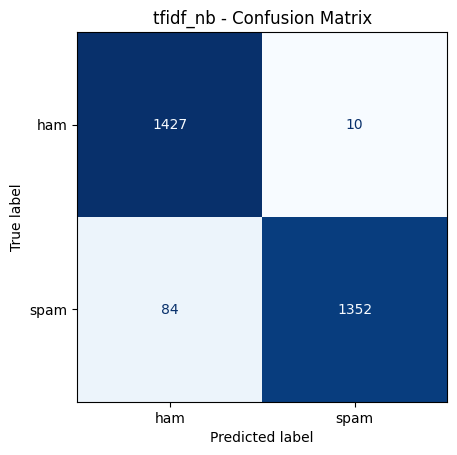

=== tfidf_lr ===
              precision    recall  f1-score   support

         ham     0.9800    0.9910    0.9855      1437
        spam     0.9908    0.9798    0.9853      1436

    accuracy                         0.9854      2873
   macro avg     0.9854    0.9854    0.9854      2873
weighted avg     0.9854    0.9854    0.9854      2873



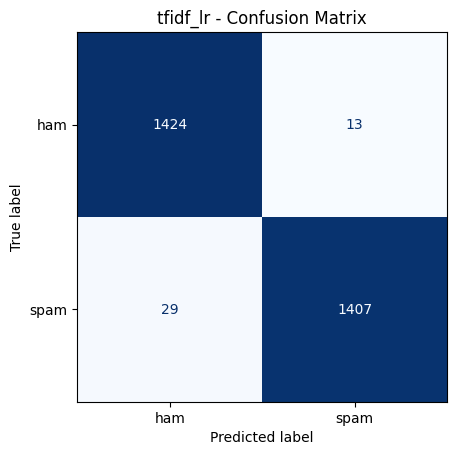

,model,accuracy,macro_f1,spam_precision,spam_recall,ham_fpr,roc_auc,ece,threshold
0,tfidf_nb,0.9673,0.9673,0.9927,0.9415,0.007,0.9943,0.0111,0.83
1,tfidf_lr,0.9854,0.9854,0.9908,0.9798,0.009,0.9990,0.0066,0.59


In [ ]:
test_results = []
test_probabilities = {}

for model_name, model in models.items():
    settings = calibration[model_name]
    probabilities = to_probability(to_logit(model.predict_proba(test_texts)[:, 1]) / settings["temperature"])
    predictions = (probabilities >= settings["threshold"]).astype(int)
    test_probabilities[model_name] = probabilities
    test_results.append(test_scores(model_name, test_labels, probabilities, settings["threshold"]))

    print(f"=== {model_name} ===")
    print(classification_report(test_labels, predictions, target_names=["ham", "spam"], digits=4))

    ConfusionMatrixDisplay.from_predictions(test_labels, predictions, display_labels=["ham", "spam"], cmap="Blues", values_format="d", colorbar=False)
    plt.title(f"{model_name} - Confusion Matrix")
    plt.savefig(os.path.join(figure_folder, f"confusion_{model_name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

display(pd.DataFrame(test_results).round(4))

In [ ]:
# Realistic spam rate: in a real inbox only about 13.4% of messages are spam.
# Add unused ham to the test set until spam is 13.4%, then measure precision again.
spam_count = (test_labels == 1).sum()
ham_needed = int(round(spam_count * (1 - 0.134) / 0.134)) - (test_labels == 0).sum()
extra_ham_texts = unused_ham_data.sample(n=ham_needed, random_state=42)["text"].apply(normalize)
all_labels = np.concatenate([test_labels, np.zeros(ham_needed, dtype=int)])

natural_results = []
for model_name, model in models.items():
    settings = calibration[model_name]
    extra_probabilities = to_probability(to_logit(model.predict_proba(extra_ham_texts)[:, 1]) / settings["temperature"])
    all_probabilities = np.concatenate([test_probabilities[model_name], extra_probabilities])
    scores = test_scores(model_name, all_labels, all_probabilities, settings["threshold"])
    natural_results.append({"model": model_name, "spam_prevalence": all_labels.mean(), "spam_precision": scores["spam_precision"],
                            "spam_recall": scores["spam_recall"], "ham_fpr": scores["ham_fpr"],
                            "false_alarms_per_1000_ham": scores["ham_fpr"] * 1000, "macro_f1": scores["macro_f1"]})

display(pd.DataFrame(natural_results).round(4))

,model,spam_prevalence,spam_precision,spam_recall,ham_fpr,false_alarms_per_1000_ham,macro_f1
0,tfidf_nb,0.134,0.9461,0.9415,0.0083,8.2974,0.9676
1,tfidf_lr,0.134,0.9571,0.9798,0.0068,6.7888,0.9817


## 7. Saving the models and results

In [ ]:
# It's accessible via My Drive (I would put it in the markdown on my github) or if you wanna to try by yourself, Sir. To run this code it will create a folder on your drive
import joblib

for model_name, model in models.items():
    path = os.path.join(model_folder, f"{model_name}.joblib")
    joblib.dump(model, path, compress=3)
    print(f"Saved: {model_name}.joblib ({os.path.getsize(path) / (1024 * 1024):.2f} MB)")

with open(calibration_path, "w") as file:
    json.dump(calibration, file, indent=2)
print("Saved: calibration.json")

save_rows(test_results, "test_results.csv")
save_rows(natural_results, "natural_prevalence.csv")

# Test predictions (0 = ham, 1 = spam), used by the transformer notebook to compare all five models
test_predictions = pd.DataFrame({"label": test_labels})
for model_name in models:
    test_predictions[model_name] = (test_probabilities[model_name] >= calibration[model_name]["threshold"]).astype(int)
test_predictions.to_csv(os.path.join(table_folder, "test_predictions.csv"), index=False)
print("Results saved:", table_folder)

Saved: tfidf_nb.joblib (0.88 MB)
Saved: tfidf_lr.joblib (1.20 MB)
Saved: calibration.json
Results saved: /content/drive/MyDrive/SpamLens/results/tables
